First five rows of dataset:
   Unnamed: 0      key  fare_amount          pickup_datetime  \
0    24238194  52:06.0          7.5  2015-05-07 19:52:06 UTC   
1    27835199  04:56.0          7.7  2009-07-17 20:04:56 UTC   
2    44984355  45:00.0         12.9  2009-08-24 21:45:00 UTC   
3    25894730  22:21.0          5.3  2009-06-26 08:22:21 UTC   
4    17610152  47:00.0         16.0  2014-08-28 17:47:00 UTC   

   pickup_longitude  pickup_latitude  dropoff_longitude  dropoff_latitude  \
0        -73.999817        40.738354         -73.999512         40.723217   
1        -73.994355        40.728225         -73.994710         40.750325   
2        -74.005043        40.740770         -73.962565         40.772647   
3        -73.976124        40.790844         -73.965316         40.803349   
4        -73.925023        40.744085         -73.973082         40.761247   

   passenger_count  
0                1  
1                1  
2                1  
3                3  
4                5 

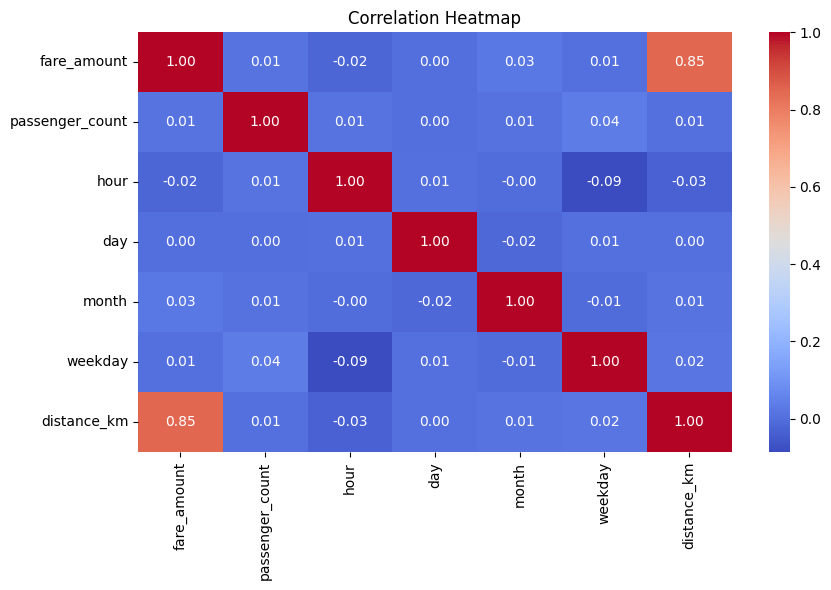


Training data: (153007, 6)
Testing data: (38252, 6)

All three models trained successfully!

 Linear Regression
R2 Score: 0.7308
RMSE: 4.181
MAE: 2.2824

 Ridge Regression
R2 Score: 0.7308
RMSE: 4.181
MAE: 2.2824

 Lasso Regression
R2 Score: 0.7308
RMSE: 4.181
MAE: 2.2826

MODEL COMPARISON:
               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.730820  4.180978  2.282412
1   Ridge Regression  0.730820  4.180979  2.282421
2   Lasso Regression  0.730814  4.181025  2.282625


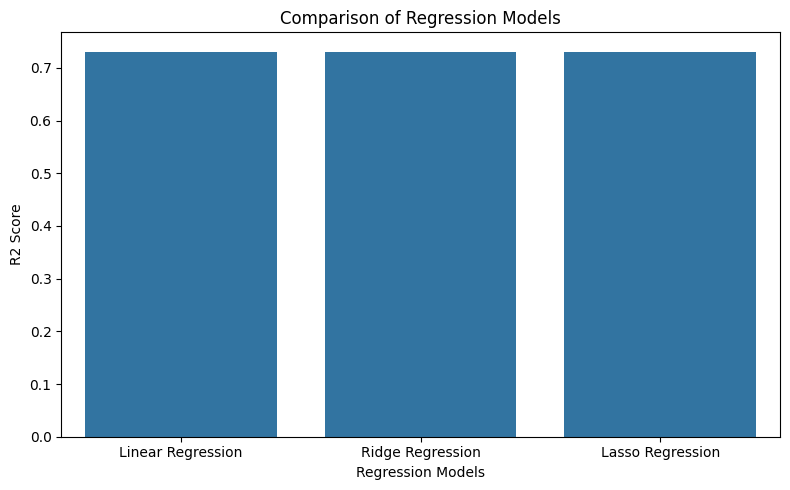

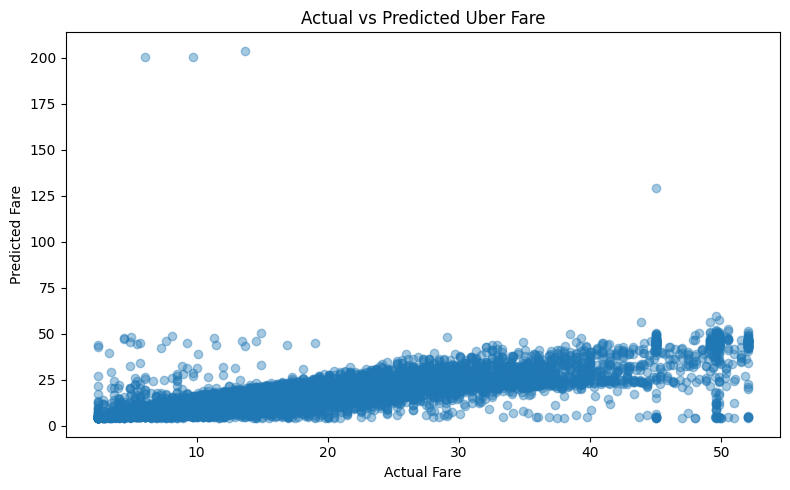


Predicted Uber Fare:
Fare Amount: $ 20.59


In [2]:
# # Install required libraries
# !pip install pandas numpy matplotlib seaborn scikit-learn



# ==========================================================
# EXPERIMENT NO. 2: REGRESSION ANALYSIS
# Aim: Predict Uber ride fare using Regression Algorithms
# Algorithms: Linear Regression, Ridge Regression, Lasso Regression
# ==========================================================


# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)


# STEP 2: Download and load the dataset

# Direct URL of Uber CSV dataset
url = "https://raw.githubusercontent.com/shaheenk2002/Uber-Fare-Dataset/main/uber.csv"

# Read CSV directly from the URL
df = pd.read_csv(url)

# Display first five rows
print("First five rows of dataset:")
print(df.head())

# Display dataset information
print("\nDataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())


# STEP 3: Data preprocessing

# Remove unnecessary index column if present
if "Unnamed: 0" in df.columns:
    df.drop("Unnamed: 0", axis=1, inplace=True)

# Remove rows containing missing values
df.dropna(inplace=True)

# Convert pickup_datetime into datetime format
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"],
    errors="coerce",
    utc=True
)

# Remove rows with invalid dates
df.dropna(subset=["pickup_datetime"], inplace=True)

# Remove invalid fare amounts
df = df[df["fare_amount"] > 0]

# Keep passenger counts between 1 and 6
df = df[
    (df["passenger_count"] >= 1) &
    (df["passenger_count"] <= 6)
]

# Remove invalid latitude and longitude values
df = df[
    df["pickup_latitude"].between(-90, 90) &
    df["dropoff_latitude"].between(-90, 90) &
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180)
]

print("\nDataset after preprocessing:", df.shape)


# STEP 4: Feature engineering

# Extract hour, day, month and weekday from pickup time

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["weekday"] = df["pickup_datetime"].dt.weekday


# STEP 5: Calculate distance using Haversine formula

def calculate_distance(lat1, lon1, lat2, lon2):

    # Convert latitude and longitude into radians
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    # Calculate difference between coordinates
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Apply Haversine formula
    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    # Earth's radius in kilometres
    radius = 6371

    return radius * c


# Calculate distance between pickup and drop-off
df["distance_km"] = calculate_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Remove zero-distance and extremely long rides
df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] <= 100)
]

print("\nDataset after distance calculation:", df.shape)


# STEP 6: Identify and remove outliers

# Calculate 99th percentile of fare amount
upper_limit = df["fare_amount"].quantile(0.99)

# Identify outliers
outliers = df[df["fare_amount"] > upper_limit]

print("\nNumber of outliers:", len(outliers))
print("Upper fare limit:", upper_limit)

# Remove outliers
df = df[df["fare_amount"] <= upper_limit]

print("Dataset after removing outliers:", df.shape)


# STEP 7: Select input features and target variable

# Independent variables (features)
X = df[
    [
        "passenger_count",
        "hour",
        "day",
        "month",
        "weekday",
        "distance_km"
    ]
]

# Dependent variable (target)
y = df["fare_amount"]


# STEP 8: Correlation analysis

# Calculate correlation between numerical columns
correlation = df[
    [
        "fare_amount",
        "passenger_count",
        "hour",
        "day",
        "month",
        "weekday",
        "distance_km"
    ]
].corr()

print("\nCorrelation matrix:")
print(correlation)

# Draw correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# STEP 9: Split dataset into training and testing data

# 80% data for training
# 20% data for testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


# STEP 10: Create regression models

# Linear Regression
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Ridge Regression
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Lasso Regression
lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.001, max_iter=10000)
)


# STEP 11: Train all three models

linear_model.fit(X_train, y_train)

ridge_model.fit(X_train, y_train)

lasso_model.fit(X_train, y_train)

print("\nAll three models trained successfully!")


# STEP 12: Predict Uber fares

linear_pred = linear_model.predict(X_test)

ridge_pred = ridge_model.predict(X_test)

lasso_pred = lasso_model.predict(X_test)


# STEP 13: Evaluate model performance

def evaluate_model(name, actual, predicted):

    # Calculate R2 score
    r2 = r2_score(actual, predicted)

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Calculate MAE
    mae = mean_absolute_error(actual, predicted)

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

    return [name, r2, rmse, mae]


# Evaluate Linear Regression
results = []

results.append(
    evaluate_model("Linear Regression", y_test, linear_pred)
)

# Evaluate Ridge Regression
results.append(
    evaluate_model("Ridge Regression", y_test, ridge_pred)
)

# Evaluate Lasso Regression
results.append(
    evaluate_model("Lasso Regression", y_test, lasso_pred)
)


# STEP 14: Compare model performance

# Create comparison table
results_df = pd.DataFrame(
    results,
    columns=["Model", "R2 Score", "RMSE", "MAE"]
)

print("\nMODEL COMPARISON:")
print(results_df)


# STEP 15: Visualize R2 scores

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of Regression Models")
plt.ylabel("R2 Score")
plt.xlabel("Regression Models")

plt.tight_layout()
plt.show()


# STEP 16: Visualize actual vs predicted fares

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    linear_pred,
    alpha=0.4
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fare")

plt.tight_layout()
plt.show()


# STEP 17: Predict fare for a new ride

# Example:
# 2 passengers
# 10 AM
# 15th day
# June
# Monday (0)
# 8 km distance

new_ride = pd.DataFrame(
    [[2, 10, 15, 6, 0, 8]],
    columns=[
        "passenger_count",
        "hour",
        "day",
        "month",
        "weekday",
        "distance_km"
    ]
)

# Predict fare using Linear Regression
predicted_fare = linear_model.predict(new_ride)

print("\nPredicted Uber Fare:")
print("Fare Amount: $", round(predicted_fare[0], 2))


# ==========================================================
# END OF EXPERIMENT NO. 2
# ==========================================================
